# Part I - Ford GoBike System Data Exploration
## by Hsin-Wen Chang

## Introduction

> This report explores individual trip records from the Bay Wheels (Ford GoBike) bike-share system for February 2019. Each row represents a single trip with duration, start/end station information, and limited rider demographics.

> The analysis goal is to understand how trip duration and demand patterns vary across rider segments and time.

> Guiding questions:

> 1. What does the distribution of trip duration look like, and are there outliers that need handling?

> 2. How do trip duration and usage behavior differ between Subscribers and Customers?

> 3. How do time-based patterns (hour/day) interact with rider type?

> 4. Does rider age show a relationship with trip duration?

## Preliminary Wrangling

This section loads the dataset, checks data quality, engineers analysis-friendly fields, and defines the core features used later in the exploration.

In [1]:
# import all packages and set plots to be embedded inline
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.simplefilter("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


def format_axis(ax, title: str, xlabel: str, ylabel: str) -> None:
    """Apply consistent chart labels and titles."""
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)


def finalize_plot() -> None:
    """Apply shared finishing touches for plots."""
    plt.tight_layout()
    plt.show()

> **Question:** What is the quality and shape of the raw trip data, and what cleaning is required before analysis?

**Wrangling plan**
- Parse datetime fields and derive time components (hour, day of week).
- Convert trip duration to minutes for easier interpretation.
- Keep realistic rider ages only (18-80) for age-based analysis.
- Preserve missing demographics where needed, but avoid injecting assumptions.

In [2]:
def load_and_wrangle_data(csv_name: str) -> pd.DataFrame:
    """Load trip data and perform core cleaning/feature engineering."""
    file_path = Path(csv_name)
    if not file_path.exists():
        raise FileNotFoundError(
            f"Could not find {csv_name}. Run this notebook from the folder containing the dataset."
        )

    df_raw = pd.read_csv(file_path)

    df = df_raw.copy()
    df["start_time"] = pd.to_datetime(df["start_time"])
    df["end_time"] = pd.to_datetime(df["end_time"])

    df["duration_min"] = df["duration_sec"] / 60
    df["start_hour"] = df["start_time"].dt.hour
    df["start_day_name"] = df["start_time"].dt.day_name()
    df["start_day_num"] = df["start_time"].dt.dayofweek

    # Build age feature only where birth year is present and plausible.
    df["member_age"] = 2019 - df["member_birth_year"]
    df.loc[~df["member_age"].between(18, 80), "member_age"] = np.nan

    weekday_order = [
        "Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"
    ]
    df["start_day_name"] = pd.Categorical(
        df["start_day_name"], categories=weekday_order, ordered=True
    )

    return df


df = load_and_wrangle_data("201902-fordgobike-tripdata.csv")

print("Rows, Columns:", df.shape)
display(df.head(3))

missing_pct = (df.isna().mean() * 100).sort_values(ascending=False).head(8)
print("\nTop missingness (%):")
display(missing_pct.round(2))

Rows, Columns: (183412, 21)


,duration_sec,start_time,end_time,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_latitude,...,bike_id,user_type,member_birth_year,member_gender,bike_share_for_all_trip,duration_min,start_hour,start_day_name,start_day_num,member_age
0,52185,2019-02-28 17:32:10.145,2019-03-01 08:01:55.975,21.0,Montgomery St BART Station (Market St at 2nd St),37.789625,-122.400811,13.0,Commercial St at Montgomery St,37.794231,...,4902,Customer,1984.0,Male,No,869.750000,17,Thursday,3,35.0
1,42521,2019-02-28 18:53:21.789,2019-03-01 06:42:03.056,23.0,The Embarcadero at Steuart St,37.791464,-122.391034,81.0,Berry St at 4th St,37.775880,...,2535,Customer,NaN,NaN,No,708.683333,18,Thursday,3,NaN
2,61854,2019-02-28 12:13:13.218,2019-03-01 05:24:08.146,86.0,Market St at Dolores St,37.769305,-122.426826,3.0,Powell St BART Station (Market St at 4th St),37.786375,...,5905,Customer,1972.0,Male,No,1030.900000,12,Thursday,3,47.0



Top missingness (%):


member_age            4.61
member_birth_year     4.51
member_gender         4.51
start_station_id      0.11
start_station_name    0.11
end_station_id        0.11
end_station_name      0.11
start_day_num         0.00
dtype: float64

### What is the structure of your dataset?

The dataset contains one row per bike trip and includes numeric, datetime, geospatial, and categorical features. Core columns include trip duration, start/end timestamps, station details, bike and rider attributes. After wrangling, engineered features include duration in minutes, trip start hour, weekday, and rider age.

### What is/are the main feature(s) of interest in your dataset?

The main features of interest are:
- `duration_min` (trip duration in minutes)
- `user_type` (Subscriber vs Customer)
- time-of-use features (`start_hour`, `start_day_name`)

### What features in the dataset do you think will help support your investigation into your feature(s) of interest?

Supporting features include `member_age`, `member_gender`, station locations, and `bike_share_for_all_trip`, since they can explain variation in duration and usage behavior across segments.

## Univariate Exploration

**Question:** How are single-variable distributions shaped, and what do they suggest about rider behavior?

**Visualizations in this section:**
1. Histogram of trip duration (minutes)
2. Count plot of rider type

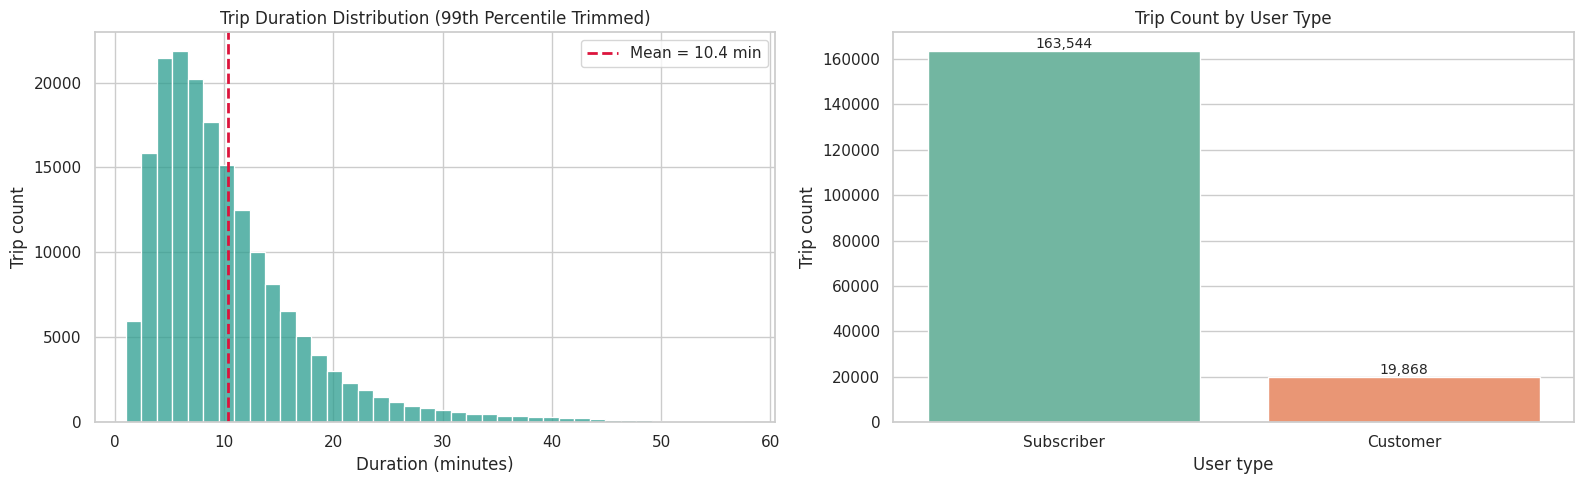

In [3]:
# Keep duration-focused charts within the 99th percentile to reduce outlier distortion.
duration_cap = df["duration_min"].quantile(0.99)
duration_core = df.loc[df["duration_min"] <= duration_cap, "duration_min"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(duration_core, bins=40, color="#2a9d8f", ax=axes[0])
axes[0].axvline(duration_core.mean(), color="crimson", linestyle="--", linewidth=2,
                label=f"Mean = {duration_core.mean():.1f} min")
format_axis(axes[0], "Trip Duration Distribution (99th Percentile Trimmed)", "Duration (minutes)", "Trip count")
axes[0].legend()

sns.countplot(data=df, x="user_type", order=df["user_type"].value_counts().index,
              palette="Set2", ax=axes[1])
format_axis(axes[1], "Trip Count by User Type", "User type", "Trip count")
for patch in axes[1].patches:
    axes[1].annotate(
        f"{int(patch.get_height()):,}",
        (patch.get_x() + patch.get_width() / 2, patch.get_height()),
        ha="center", va="bottom", fontsize=10
    )

finalize_plot()

### Discuss the distribution(s) of your variable(s) of interest. Were there any unusual points? Did you need to perform any transformations?

Trip duration is strongly right-skewed, with a long tail of unusually long rides. To prevent these rare trips from dominating visuals, I used a 99th-percentile cap for several plots while keeping the full data in memory for context. No logarithmic transform was strictly required for exploratory readability, though it may be useful in modeling.

### Of the features you investigated, were there any unusual distributions? Did you perform any operations on the data to tidy, adjust, or change the form of the data? If so, why did you do this?

`user_type` is imbalanced, with Subscribers making most trips. For demographics, some birth year and gender values are missing. I engineered `member_age` and restricted it to a plausible range (18-80) to remove obvious data quality artifacts and improve interpretability.

## Bivariate Exploration

**Question:** How does trip duration vary across rider groups and rider age, and what joint category patterns appear?

**Visualizations in this section:**
1. Jittered scatter + trend: age vs duration
2. Box plot: duration by user type
3. Heatmap: normalized trip share by user type and weekday
4. Binned median summary: age-bin median duration by user type

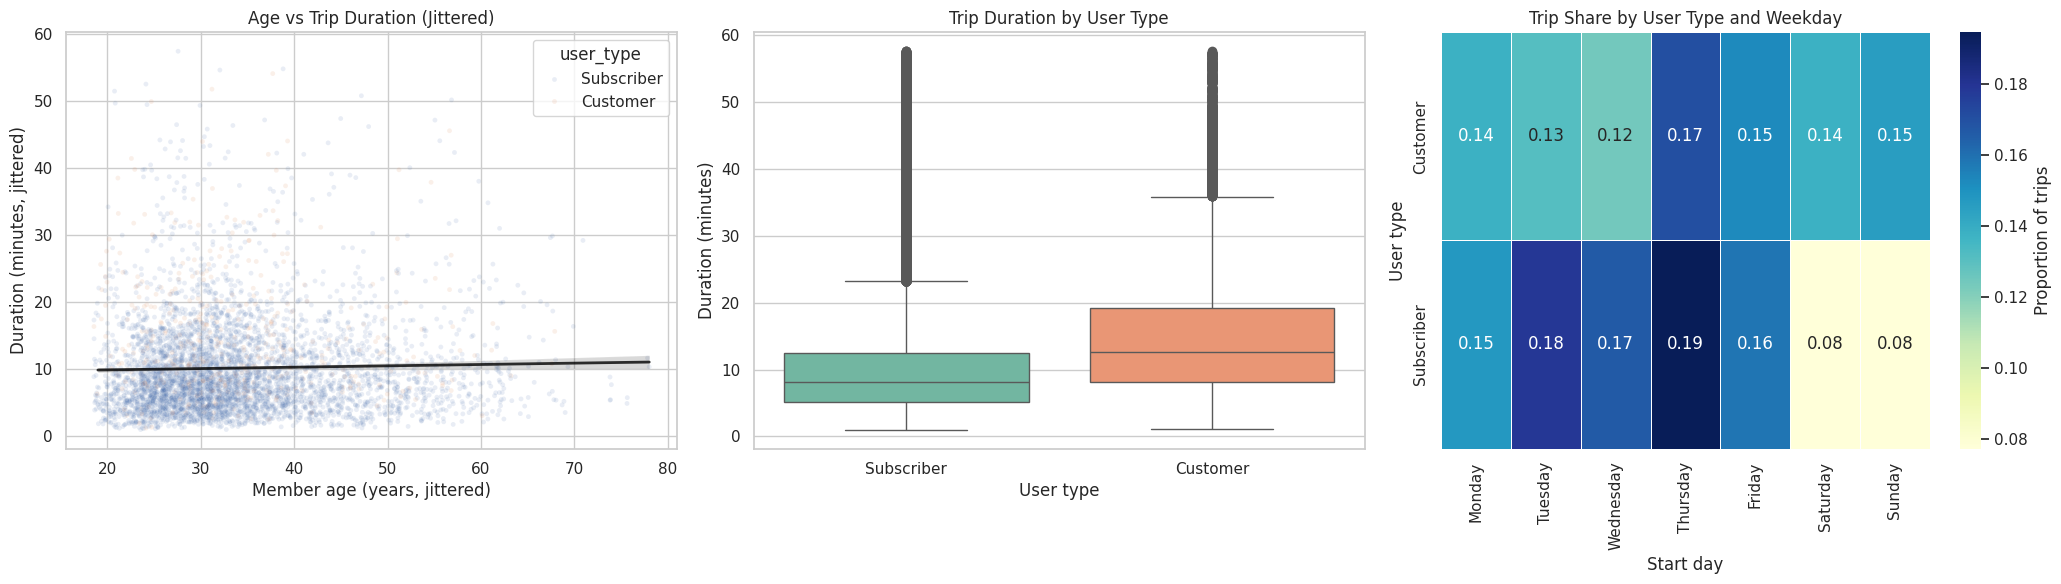

In [4]:
# Use stronger jitter and controlled sampling to reduce overplotting in age-duration view.
scatter_df = df[["member_age", "duration_min", "user_type"]].dropna().copy()
scatter_df = scatter_df[scatter_df["duration_min"] <= duration_cap].sample(
    n=min(5000, len(scatter_df)), random_state=42
)
rng = np.random.default_rng(42)
scatter_df["member_age_jitter"] = scatter_df["member_age"] + rng.uniform(-0.45, 0.45, len(scatter_df))
scatter_df["duration_jitter"] = scatter_df["duration_min"] + rng.uniform(-0.15, 0.15, len(scatter_df))

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# 1) Jittered scatter + trend line
sns.scatterplot(
    data=scatter_df, x="member_age_jitter", y="duration_jitter", hue="user_type",
    alpha=0.12, s=12, ax=axes[0]
    )
sns.regplot(
    data=scatter_df, x="member_age", y="duration_min",
    scatter=False, color="black", line_kws={"linewidth": 2, "alpha": 0.8}, ax=axes[0]
    )
format_axis(axes[0], "Age vs Trip Duration (Jittered)", "Member age (years, jittered)", "Duration (minutes, jittered)")

# 2) Box plot
box_df = df[df["duration_min"] <= duration_cap]
sns.boxplot(data=box_df, x="user_type", y="duration_min", palette="Set2", ax=axes[1])
format_axis(axes[1], "Trip Duration by User Type", "User type", "Duration (minutes)")

# 3) Heatmap of normalized shares
heat_df = (
    df.groupby(["user_type", "start_day_name"]).size()
    .groupby(level=0).transform(lambda x: x / x.sum())
    .rename("share")
    .reset_index()
    .pivot(index="user_type", columns="start_day_name", values="share")
)
sns.heatmap(
    heat_df, cmap="YlGnBu", annot=True, fmt=".2f", linewidths=0.5,
    cbar_kws={"label": "Proportion of trips"}, ax=axes[2]
    )
format_axis(axes[2], "Trip Share by User Type and Weekday", "Start day", "User type")

finalize_plot()

### Additional Bivariate Summary for Explanatory Reuse

The following binned age-summary chart is included so the Part II explanatory Visualization 3 is directly sourced from Part I.

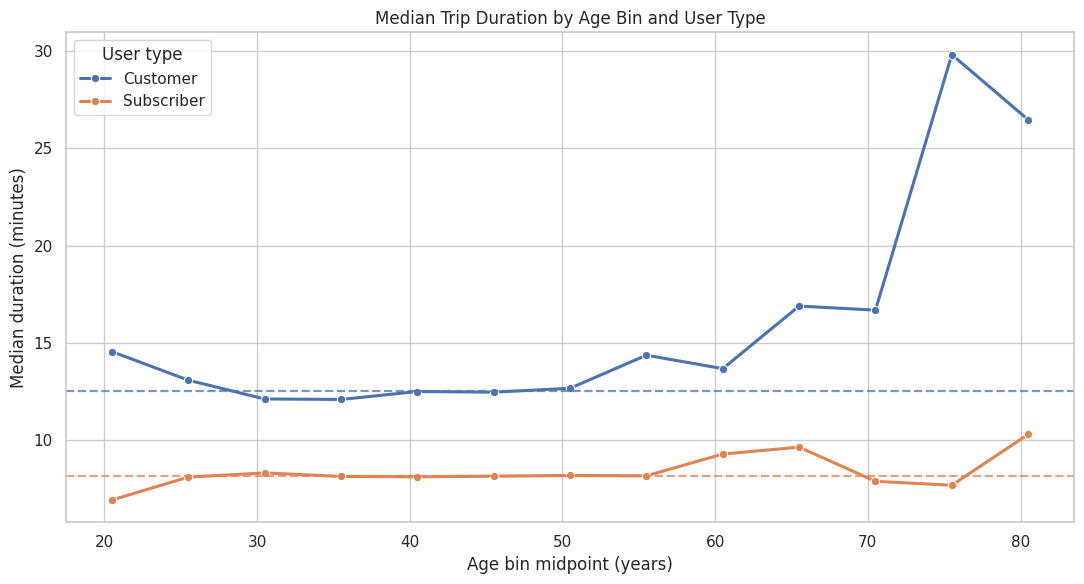

In [5]:
summary_df = df[["member_age", "duration_min", "user_type"]].dropna().copy()
summary_df = summary_df[summary_df["duration_min"] <= duration_cap]

age_bins = np.arange(18, 86, 5)
summary_df["age_bin"] = pd.cut(
    summary_df["member_age"], bins=age_bins, right=False, include_lowest=True
)
summary_df = summary_df.dropna(subset=["age_bin"])

age_profile = (
    summary_df.groupby(["age_bin", "user_type"], observed=True)["duration_min"]
    .median()
    .reset_index(name="median_duration")
)
age_profile["age_mid"] = age_profile["age_bin"].apply(lambda interval: interval.left + 2.5)

type_medians = (
    summary_df.groupby("user_type", as_index=False)["duration_min"]
    .median()
    .rename(columns={"duration_min": "overall_median"})
)

plt.figure(figsize=(11, 6))
sns.lineplot(
    data=age_profile, x="age_mid", y="median_duration", hue="user_type",
    marker="o", linewidth=2.2, markersize=6
)

palette = dict(zip(type_medians["user_type"], sns.color_palette(n_colors=len(type_medians))))
for _, row in type_medians.iterrows():
    plt.axhline(
        row["overall_median"], linestyle="--", linewidth=1.6,
        color=palette.get(row["user_type"], "gray"), alpha=0.75
    )

plt.title("Median Trip Duration by Age Bin and User Type")
plt.xlabel("Age bin midpoint (years)")
plt.ylabel("Median duration (minutes)")
plt.legend(title="User type")
plt.tight_layout()
plt.show()

### Talk about some of the relationships you observed in this part of the investigation. How did the feature(s) of interest vary with other features in the dataset?

Customers generally show longer trips than Subscribers, while Subscribers dominate total trip volume. The scatter plot suggests a weak negative relationship between age and duration, but with considerable spread.

### Did you observe any interesting relationships between the other features (not the main feature(s) of interest)?

The weekday heatmap indicates clear behavioral differences by user type: Subscribers are relatively weekday-heavy (commute pattern), while Customers are more balanced and comparatively stronger on weekends.

## Multivariate Exploration

**Question:** How do duration patterns change when combining rider type, time-of-use, and rider demographics?

**Visualizations in this section:**
1. Facet plot: duration distributions by user type
2. Density plot matrix: numeric relationships segmented by user type
3. Box + median summary: duration by start hour and user type

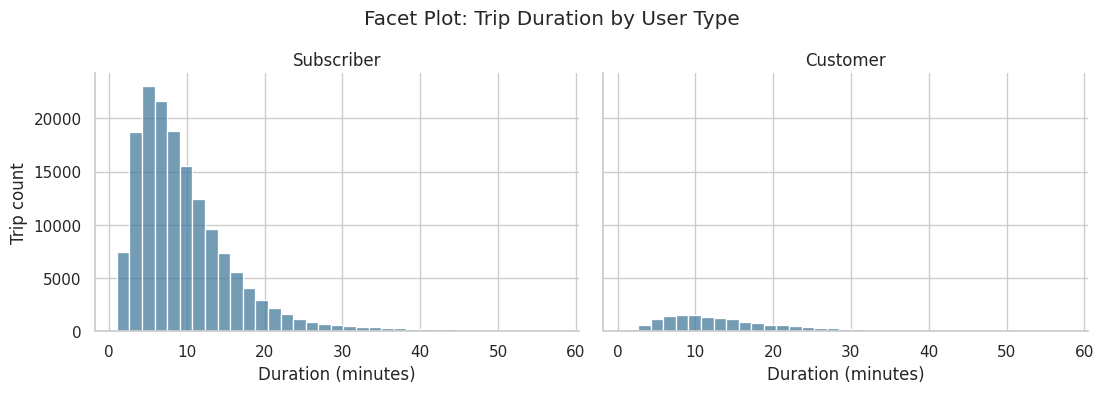

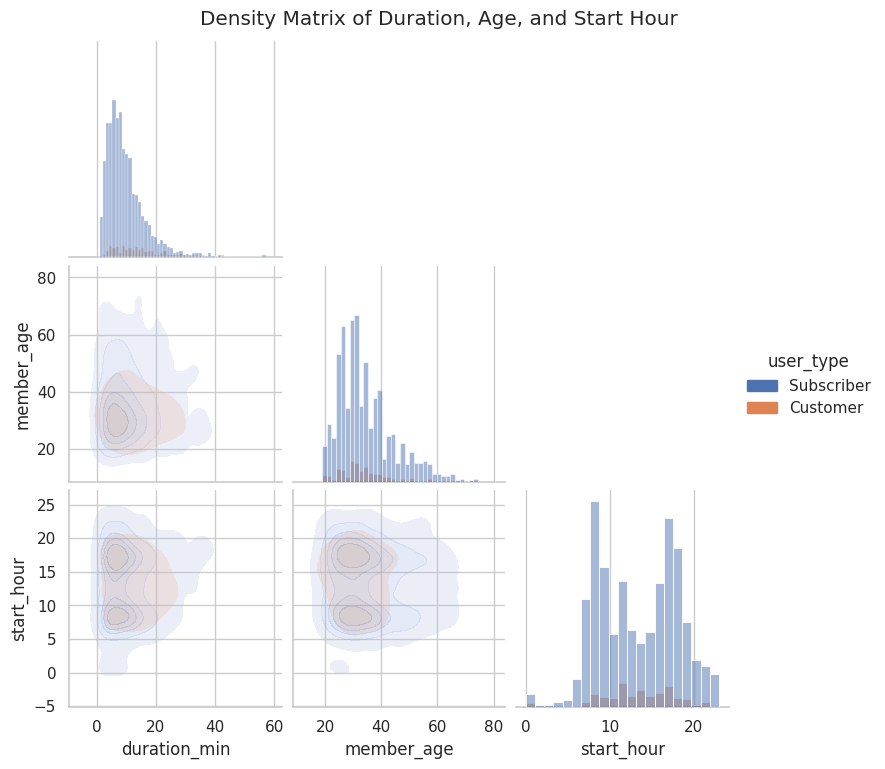

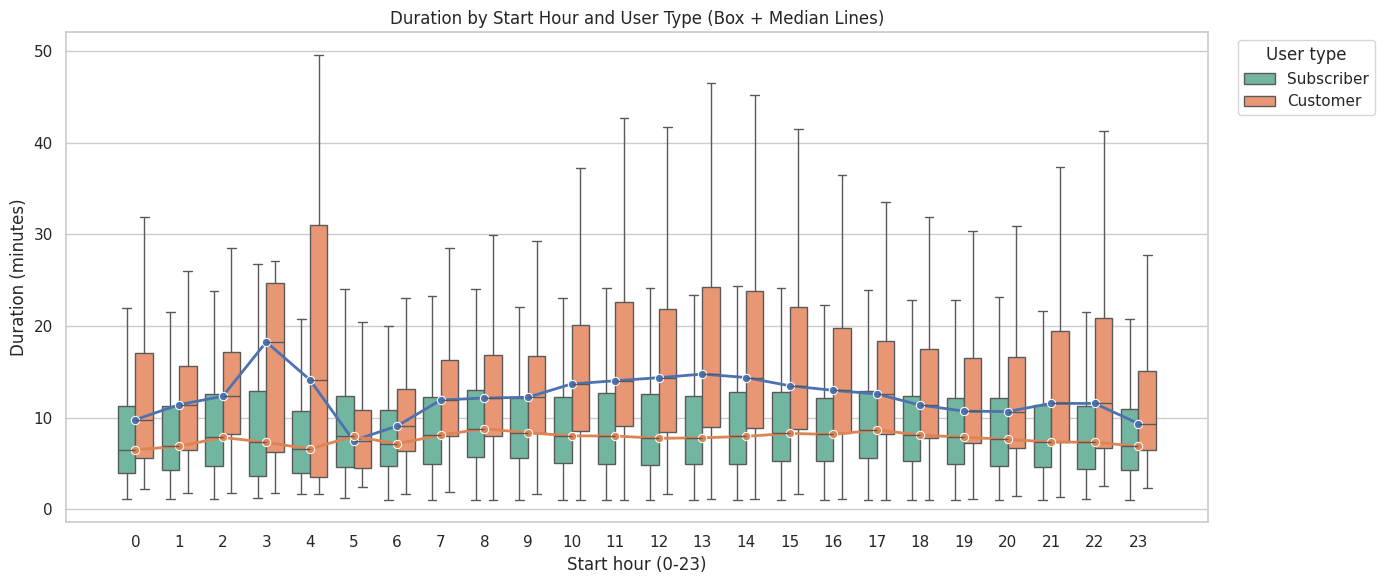

In [6]:
multi_df = df[(df["duration_min"] <= duration_cap) & (df["member_age"].notna())].copy()

# 1) Facet plot
g = sns.FacetGrid(
    data=multi_df, col="user_type", height=4, aspect=1.4, sharex=True, sharey=True
    )
g.map_dataframe(sns.histplot, x="duration_min", bins=35, color="#457b9d")
g.set_axis_labels("Duration (minutes)", "Trip count")
g.set_titles("{col_name}")
g.fig.subplots_adjust(top=0.82)
g.fig.suptitle("Facet Plot: Trip Duration by User Type")
plt.show()

# 2) Density plot matrix to avoid overplotted point clouds
pair_features = ["duration_min", "member_age", "start_hour"]
pair_df = multi_df[pair_features + ["user_type"]].dropna().sample(
    n=min(3000, len(multi_df)), random_state=7
)
sns.pairplot(
    pair_df, vars=pair_features, hue="user_type", kind="kde",
    diag_kind="hist", corner=True, plot_kws={"fill": True, "alpha": 0.25, "levels": 6}
    )
plt.suptitle("Density Matrix of Duration, Age, and Start Hour", y=1.02)
plt.show()

# 3) Duration summary by hour and user type (box + median lines)
hour_df = multi_df.copy()
hour_df["start_hour"] = hour_df["start_hour"].astype(int)

fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(
    data=hour_df, x="start_hour", y="duration_min", hue="user_type",
    showfliers=False, palette="Set2", ax=ax
    )

median_hour = (
    hour_df.groupby(["start_hour", "user_type"], as_index=False)["duration_min"]
    .median()
    .rename(columns={"duration_min": "median_duration"})
)
sns.lineplot(
    data=median_hour, x="start_hour", y="median_duration", hue="user_type",
    marker="o", linewidth=2, legend=False, ax=ax
    )

format_axis(ax, "Duration by Start Hour and User Type (Box + Median Lines)", "Start hour (0-23)", "Duration (minutes)")
ax.legend(title="User type", bbox_to_anchor=(1.02, 1), loc="upper left")
finalize_plot()

### Talk about some of the relationships you observed in this part of the investigation. Were there features that strengthened each other in terms of looking at your feature(s) of interest?

Combining rider type with time and demographics sharpened the interpretation: user type consistently explains both trip volume and duration distribution, while start hour and age add secondary structure. In particular, subscribers concentrate activity during commute-like hours and generally shorter durations.

### Were there any interesting or surprising interactions between features?

The most notable interaction is that longer trips are more frequent outside classic commute patterns and among Customer trips. Age contributes less strongly than expected compared with rider type and time-of-day effects.

## Conclusions

### Summary of main findings
- Trip duration is right-skewed with a long tail; most trips are relatively short.
- Subscribers account for most trips and tend to have shorter durations than Customers.
- The duration gap is clear in summary statistics: Subscriber median duration is **8.17** minutes versus **13.20** minutes for Customers; Subscriber mean duration is **10.67** minutes versus **23.87** minutes for Customers.
- Day-of-week usage differs by user type, consistent with commute-heavy subscriber behavior.
- Age has a weak relationship with duration compared with user type and trip timing.

### Reflection on exploration steps
- The analysis started with data quality checks and feature engineering to ensure clean inputs.
- I used percentile trimming for visualization clarity while preserving original records for context.
- Progressed from univariate to bivariate to multivariate plots to validate and refine hypotheses.
- The final step was selecting the strongest, story-ready insights for an explanatory presentation.

## Export Notes

Export this notebook as HTML or PDF using Jupyter menu options after execution order is finalized. Ensure charts and markdown narrative are visible in the exported report.

In [7]:
# Quick diagnostic table used for validating narrative claims.
summary_table = (
    df.groupby("user_type")
    .agg(
        trips=("duration_sec", "size"),
        median_duration_min=("duration_min", "median"),
        mean_duration_min=("duration_min", "mean")
    )
    .sort_values("trips", ascending=False)
    .round(2)
)
display(summary_table)

,trips,median_duration_min,mean_duration_min
user_type,,,
Subscriber,163544,8.17,10.67
Customer,19868,13.20,23.87


In [8]:
# Final reproducibility check
required_columns = [
    "duration_min", "start_hour", "start_day_name", "member_age", "user_type"
]
missing_required = [c for c in required_columns if c not in df.columns]
assert not missing_required, f"Missing required columns: {missing_required}"
print("Notebook setup check passed.")

Notebook setup check passed.
